In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
n
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [1]:
import pandas as pd
import os

DATA_DIR = "../data/raw/NIH_ChestXray14"

csv_path = os.path.join(DATA_DIR, "Data_Entry_2017_v2020.csv")

df = pd.read_csv(csv_path)

print("Number of images:", len(df))
print("Number of patients:", df["Patient ID"].nunique())
print()
print("Columns:")
print(df.columns.tolist())

Number of images: 112120
Number of patients: 30805

Columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']


In [3]:
df.head()

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


In [4]:
df["Finding Labels"].head(20)

0               Cardiomegaly
1     Cardiomegaly|Emphysema
2      Cardiomegaly|Effusion
3                 No Finding
4                     Hernia
5                     Hernia
6        Hernia|Infiltration
7                     Hernia
8                     Hernia
9                     Hernia
10                    Hernia
11                    Hernia
12               Mass|Nodule
13                No Finding
14                No Finding
15                No Finding
16                No Finding
17                No Finding
18                No Finding
19              Infiltration
Name: Finding Labels, dtype: str

In [5]:
from collections import Counter

counter = Counter()

for labels in df["Finding Labels"]:
    for label in labels.split("|"):
        counter[label] += 1

label_counts = pd.DataFrame(
    counter.items(),
    columns=["Disease", "Count"]
).sort_values("Count", ascending=False)

display(label_counts)

,Disease,Count
3,No Finding,60361
5,Infiltration,19894
2,Effusion,13317
8,Atelectasis,11559
7,Nodule,6331
6,Mass,5782
9,Pneumothorax,5302
14,Consolidation,4667
10,Pleural_Thickening,3385
0,Cardiomegaly,2776


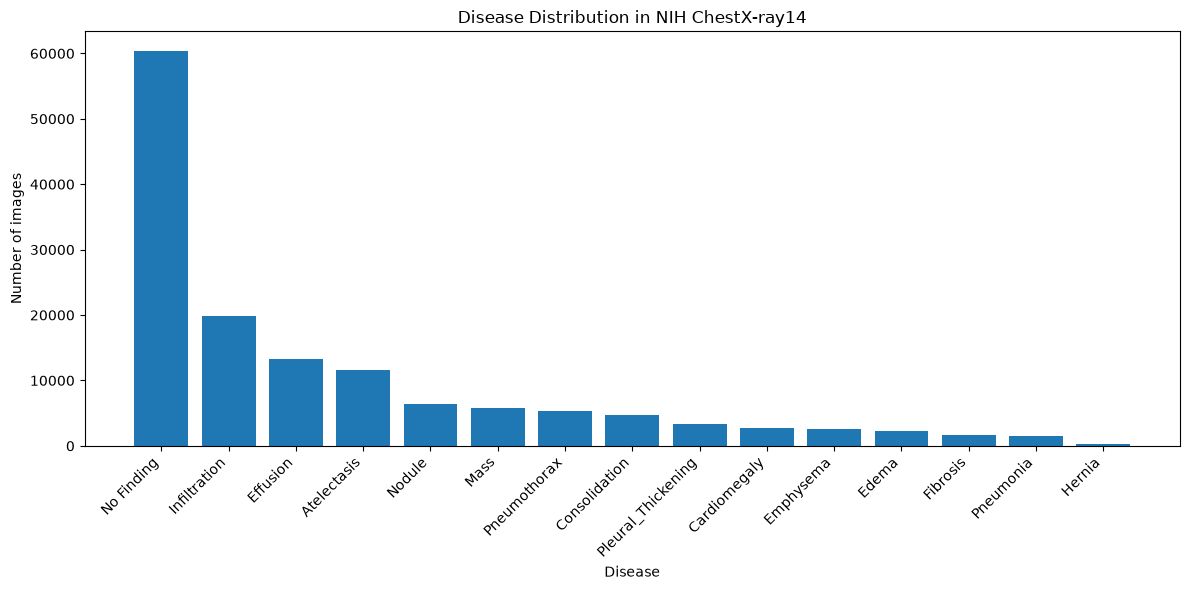

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    label_counts["Disease"],
    label_counts["Count"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Disease")
plt.ylabel("Number of images")
plt.title("Disease Distribution in NIH ChestX-ray14")
plt.tight_layout()
plt.show()

Decide the target diseases

In [7]:
TARGET_LABELS = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

print("Target diseases:")
for i, label in enumerate(TARGET_LABELS, 1):
    print(i, label)

Target diseases:
1 Atelectasis
2 Cardiomegaly
3 Effusion
4 Infiltration
5 Pneumonia


Create the multilabel targets

In [8]:
for label in TARGET_LABELS:
    df[label] = df["Finding Labels"].apply(
        lambda x: 1 if label in x.split("|") else 0
    )

df[TARGET_LABELS].head()

,Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia
0,0,1,0,0,0
1,0,1,0,0,0
2,0,1,1,0,0
3,0,0,0,0,0
4,0,0,0,0,0


Check the target distribution

In [9]:
df[TARGET_LABELS].sum().sort_values(ascending=False)

Infiltration    19894
Effusion        13317
Atelectasis     11559
Cardiomegaly     2776
Pneumonia        1431
dtype: int64

In [10]:
df[TARGET_LABELS].mean() * 100

Atelectasis     10.309490
Cardiomegaly     2.475919
Effusion        11.877453
Infiltration    17.743489
Pneumonia        1.276311
dtype: float64

Check the patient information

In [13]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Pneumonia']


In [15]:
df[[
    "Patient ID",
    "Patient Age",
    "Patient Sex",
    "View Position"
]].head(10)

,Patient ID,Patient Age,Patient Sex,View Position
0,1,57,M,PA
1,1,58,M,PA
2,1,58,M,PA
3,2,80,M,PA
4,3,74,F,PA
5,3,75,F,PA
6,3,76,F,PA
7,3,77,F,PA
8,3,78,F,PA
9,3,79,F,PA


Clean the age column

In [16]:
print(df["Patient Age"].describe())

count    112120.000000
mean         46.626365
std          16.602680
min           0.000000
25%          34.000000
50%          49.000000
75%          59.000000
max          95.000000
Name: Patient Age, dtype: float64


In [17]:
print("Minimum age:", df["Patient Age"].min())
print("Maximum age:", df["Patient Age"].max())

Minimum age: 0
Maximum age: 95


In [18]:
df["Patient Age"] = pd.to_numeric(
    df["Patient Age"],
    errors="coerce"
)

In [19]:
print(df["Patient Age"].isna().sum())

0


Check gender and view position

In [21]:
print(df["Patient Sex"].value_counts(dropna=False))

Patient Sex
M    63340
F    48780
Name: count, dtype: int64


In [22]:
print(df["View Position"].value_counts(dropna=False))

View Position
PA    67310
AP    44810
Name: count, dtype: int64


Load the official test list

In [2]:
import os

DATA_DIR = "../data/raw/NIH_ChestXray14"

test_file = os.path.join(DATA_DIR, "test_list.txt")

with open(test_file, "r") as f:
    test_images = [line.strip() for line in f.readlines()]

print("Number of test images:", len(test_images))
print("First 10:")
print(test_images[:10])

Number of test images: 25596
First 10:
['00000003_000.png', '00000003_001.png', '00000003_002.png', '00000003_003.png', '00000003_004.png', '00000003_005.png', '00000003_006.png', '00000003_007.png', '00000013_000.png', '00000013_001.png']


Load the train/validation list

In [3]:
trainval_file = os.path.join(DATA_DIR, "train_val_list.txt")

with open(trainval_file, "r") as f:
    trainval_images = [line.strip() for line in f.readlines()]

print("Number of train/validation images:", len(trainval_images))
print("First 10:")
print(trainval_images[:10])

Number of train/validation images: 86524
First 10:
['00000001_000.png', '00000001_001.png', '00000001_002.png', '00000002_000.png', '00000004_000.png', '00000005_000.png', '00000005_001.png', '00000005_002.png', '00000005_003.png', '00000005_004.png']


Add a split column

In [4]:
df["split"] = "unknown"

df.loc[df["Image Index"].isin(test_images), "split"] = "test"
df.loc[df["Image Index"].isin(trainval_images), "split"] = "train_val"

print(df["split"].value_counts())

split
train_val    86524
test         25596
Name: count, dtype: int64


Create validation split

In [6]:
trainval_df = df[df["split"] == "train_val"].copy()

print("Train/validation images:", len(trainval_df))
print("Patients:", trainval_df["Patient ID"].nunique())

Train/validation images: 86524
Patients: 28008


Patient-level train/validation split

In [7]:
from sklearn.model_selection import train_test_split

patients = trainval_df["Patient ID"].unique()

train_patients, val_patients = train_test_split(
    patients,
    test_size=0.20,
    random_state=42
)

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))

Training patients: 22406
Validation patients: 5602


In [8]:
train_df = trainval_df[
    trainval_df["Patient ID"].isin(train_patients)
].copy()

val_df = trainval_df[
    trainval_df["Patient ID"].isin(val_patients)
].copy()

test_df = df[df["split"] == "test"].copy()

In [29]:
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Training images: 69625
Validation images: 16899
Test images: 25596


Verify there is NO patient leakage

In [30]:
train_ids = set(train_df["Patient ID"])
val_ids = set(val_df["Patient ID"])
test_ids = set(test_df["Patient ID"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


Save the processed splits

In [31]:
PROCESSED_DIR = "../data/processed"

os.makedirs(PROCESSED_DIR, exist_ok=True)

train_df.to_csv(
    os.path.join(PROCESSED_DIR, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(PROCESSED_DIR, "val.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(PROCESSED_DIR, "test.csv"),
    index=False
)

print("Train, validation and test CSV files saved.")

Train, validation and test CSV files saved.


In [2]:
import pandas as pd
import os

PROCESSED_DIR = "../data/processed"

train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nFirst 3 training samples:")
display(train_df.head(3))

Train shape: (69625, 17)
Validation shape: (16899, 17)
Test shape: (25596, 17)

Train columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Pneumonia', 'split']

First 3 training samples:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143,0,1,0,0,0,train_val
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,0,1,0,0,0,train_val
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,0,1,1,0,0,train_val


Load the processed splits

In [9]:
import pandas as pd
import os

PROCESSED_DIR = "../data/processed"

train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (69625, 17)
Validation shape: (16899, 17)
Test shape: (25596, 17)


In [4]:
print("Train:")
display(train_df.head())

print("\nValidation:")
display(val_df.head())

print("\nTest:")
display(test_df.head())

Train:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143,0,1,0,0,0,train_val
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,0,1,0,0,0,train_val
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,0,1,1,0,0,train_val
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171,0,0,0,0,0,train_val
4,00000004_000.png,Mass|Nodule,0,4,82,M,AP,2500,2048,0.168,0.168,0,0,0,0,0,train_val



Validation:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000005_000.png,No Finding,0,5,69,F,PA,2048,2500,0.168,0.168,0,0,0,0,0,train_val
1,00000005_001.png,No Finding,1,5,69,F,AP,2500,2048,0.168,0.168,0,0,0,0,0,train_val
2,00000005_002.png,No Finding,2,5,69,F,AP,2500,2048,0.168,0.168,0,0,0,0,0,train_val
3,00000005_003.png,No Finding,3,5,69,F,PA,2992,2991,0.143,0.143,0,0,0,0,0,train_val
4,00000005_004.png,No Finding,4,5,70,F,PA,2986,2991,0.143,0.143,0,0,0,0,0,train_val



Test:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168,0,0,0,0,0,test
1,00000003_002.png,Hernia,1,3,75,F,PA,2048,2500,0.168,0.168,0,0,0,0,0,test
2,00000003_003.png,Hernia|Infiltration,2,3,76,F,PA,2698,2991,0.143,0.143,0,0,0,1,0,test
3,00000003_004.png,Hernia,3,3,77,F,PA,2500,2048,0.168,0.168,0,0,0,0,0,test
4,00000003_005.png,Hernia,4,3,78,F,PA,2686,2991,0.143,0.143,0,0,0,0,0,test


In [35]:
required_columns = [
    "Image Index",
    "Patient ID",
    "Patient Age",
    "Patient Sex",
    "View Position",
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

print("Missing columns:", missing_columns)

Missing columns: []


Verify patient-level separation

In [36]:
train_patients = set(train_df["Patient ID"])
val_patients = set(val_df["Patient ID"])
test_patients = set(test_df["Patient ID"])

print("Train patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))

Train patients: 22406
Validation patients: 5602
Test patients: 2797


In [37]:
print("Train ∩ Validation:", len(train_patients & val_patients))
print("Train ∩ Test:", len(train_patients & test_patients))
print("Validation ∩ Test:", len(val_patients & test_patients))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


Check label distribution in each split

In [38]:
TARGET_LABELS = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

train_counts = train_df[TARGET_LABELS].sum()
val_counts = val_df[TARGET_LABELS].sum()
test_counts = test_df[TARGET_LABELS].sum()

distribution = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
})

display(distribution)

,Train,Validation,Test
Atelectasis,6575,1705,3279
Cardiomegaly,1351,356,1069
Effusion,6964,1695,4658
Infiltration,11201,2581,6112
Pneumonia,690,186,555


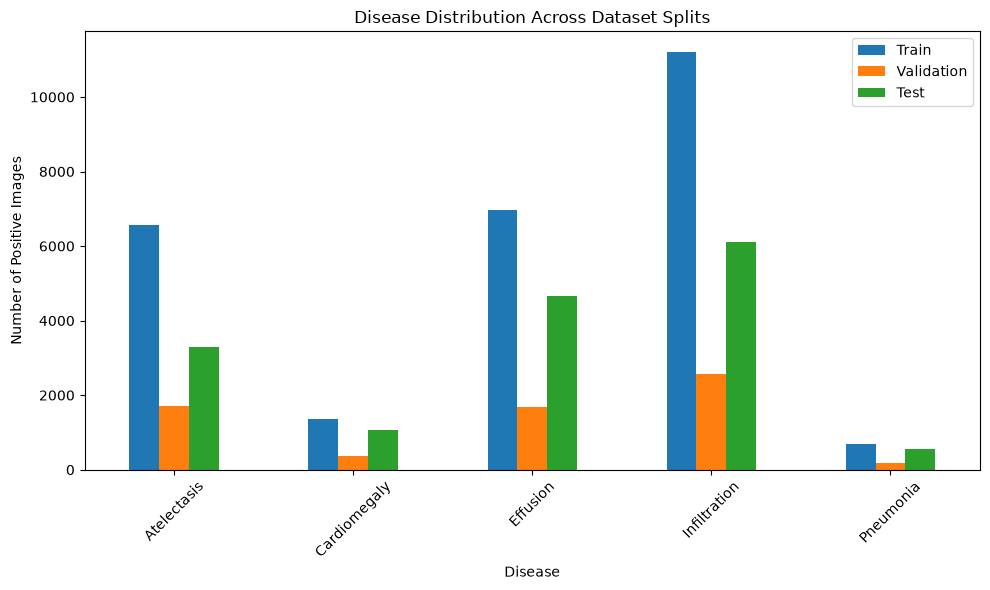

In [39]:
import matplotlib.pyplot as plt

distribution.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Disease")
plt.ylabel("Number of Positive Images")
plt.title("Disease Distribution Across Dataset Splits")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Check clinical metadata

In [40]:
## Age

print("Train age statistics:")
print(train_df["Patient Age"].describe())

print("\nValidation age statistics:")
print(val_df["Patient Age"].describe())

print("\nTest age statistics:")
print(test_df["Patient Age"].describe())

Train age statistics:
count    69625.000000
mean        46.598276
std         16.699024
min          0.000000
25%         34.000000
50%         48.000000
75%         59.000000
max         95.000000
Name: Patient Age, dtype: float64

Validation age statistics:
count    16899.000000
mean        46.600036
std         16.551597
min          0.000000
25%         34.000000
50%         49.000000
75%         59.000000
max         93.000000
Name: Patient Age, dtype: float64

Test age statistics:
count    25596.000000
mean        46.720152
std         16.372221
min          0.000000
25%         34.000000
50%         49.000000
75%         59.000000
max         92.000000
Name: Patient Age, dtype: float64


In [41]:
## Sex

print("Train:")
print(train_df["Patient Sex"].value_counts(dropna=False))

print("\nValidation:")
print(val_df["Patient Sex"].value_counts(dropna=False))

print("\nTest:")
print(test_df["Patient Sex"].value_counts(dropna=False))

Train:
Patient Sex
M    39366
F    30259
Name: count, dtype: int64

Validation:
Patient Sex
M    9092
F    7807
Name: count, dtype: int64

Test:
Patient Sex
M    14882
F    10714
Name: count, dtype: int64


In [42]:
## View Position

print("Train:")
print(train_df["View Position"].value_counts(dropna=False))

print("\nValidation:")
print(val_df["View Position"].value_counts(dropna=False))

print("\nTest:")
print(test_df["View Position"].value_counts(dropna=False))

Train:
View Position
PA    45104
AP    24521
Name: count, dtype: int64

Validation:
View Position
PA    11110
AP     5789
Name: count, dtype: int64

Test:
View Position
AP    14500
PA    11096
Name: count, dtype: int64


Check whether images are available

In [10]:
RAW_DIR = "../data/raw/NIH_ChestXray14"

print(os.listdir(RAW_DIR))

['Data_Entry_2017_v2020.csv', 'images', 'test_list.txt', 'train_val_list.txt']


In [44]:
for root, dirs, files in os.walk(RAW_DIR):
    print(root, "->", len(files), "files")
    
    if len(files) > 0:
        print("Example files:", files[:5])

../data/raw/NIH_ChestXray14 -> 3 files
Example files: ['Data_Entry_2017_v2020.csv', 'test_list.txt', 'train_val_list.txt']


Find the image directory

In [17]:
import os

RAW_DIR = "../data/raw/NIH_ChestXray14"

print("Dataset directory:")
print(os.path.abspath(RAW_DIR))

print("\nContents:")
for item in os.listdir(RAW_DIR):
    print(item)

Dataset directory:
c:\Users\jinal\OneDrive\DL Project\AdaptiveMultimodalDL\data\raw\NIH_ChestXray14

Contents:
Data_Entry_2017_v2020.csv
images
test_list.txt
train_val_list.txt


In [18]:
import os

IMAGE_ROOT = "../data/raw/NIH_ChestXray14/images"

os.makedirs(IMAGE_ROOT, exist_ok=True)

print("Image folder created:")
print(os.path.abspath(IMAGE_ROOT))

Image folder created:
c:\Users\jinal\OneDrive\DL Project\AdaptiveMultimodalDL\data\raw\NIH_ChestXray14\images


In [21]:
all_required_images = set(
    train_df["Image Index"]
).union(
    set(val_df["Image Index"])
).union(
    set(test_df["Image Index"])
)

print("Total unique images required:", len(all_required_images))

Total unique images required: 112120


In [50]:
print("Example required images:")

for image_name in list(all_required_images)[:20]:
    print(image_name)

Example required images:
00000798_021.png
00010683_007.png
00010475_041.png
00000499_010.png
00009321_015.png
00025395_002.png
00030786_005.png
00007987_000.png
00013342_008.png
00002201_007.png
00018228_000.png
00013218_000.png
00027776_000.png
00014294_009.png
00027100_000.png
00001029_016.png
00021894_000.png
00010585_027.png
00002048_000.png
00015423_003.png


In [7]:
import os

RAW_DIR = "../data/raw/NIH_ChestXray14"

image_files = []

for root, dirs, files in os.walk(RAW_DIR):
    for file in files:
        if file.lower().endswith(".png"):
            image_files.append(os.path.join(root, file))

print("Total PNG images found:", len(image_files))

print("\nFirst 10 images:")
for path in image_files[:10]:
    print(path)

Total PNG images found: 102120

First 10 images:
../data/raw/NIH_ChestXray14\images\00000001_000.png
../data/raw/NIH_ChestXray14\images\00000001_001.png
../data/raw/NIH_ChestXray14\images\00000001_002.png
../data/raw/NIH_ChestXray14\images\00000002_000.png
../data/raw/NIH_ChestXray14\images\00000003_000.png
../data/raw/NIH_ChestXray14\images\00000003_001.png
../data/raw/NIH_ChestXray14\images\00000003_002.png
../data/raw/NIH_ChestXray14\images\00000003_003.png
../data/raw/NIH_ChestXray14\images\00000003_004.png
../data/raw/NIH_ChestXray14\images\00000003_005.png


In [6]:
required_images = set(train_df["Image Index"]) | \
                  set(val_df["Image Index"]) | \
                  set(test_df["Image Index"])

found_image_names = {
    os.path.basename(path)
    for path in image_files
}

missing_images = required_images - found_image_names

print("Required images:", len(required_images))
print("Found images:", len(found_image_names))
print("Missing images:", len(missing_images))

Required images: 112120
Found images: 102120
Missing images: 10000


In [8]:
IMAGE_DIR = "../data/raw/NIH_ChestXray14/images"

print("Image directory:", os.path.abspath(IMAGE_DIR))

Image directory: c:\Users\jinal\OneDrive\DL Project\AdaptiveMultimodalDL\data\raw\NIH_ChestXray14\images


In [8]:
from PIL import Image

test_image = os.path.join(
    IMAGE_DIR,
    train_df.iloc[0]["Image Index"]
)

image = Image.open(test_image)

print("Image:", train_df.iloc[0]["Image Index"])
print("Size:", image.size)
print("Mode:", image.mode)

Image: 00000001_000.png
Size: (1024, 1024)
Mode: L


Display an actual X-ray

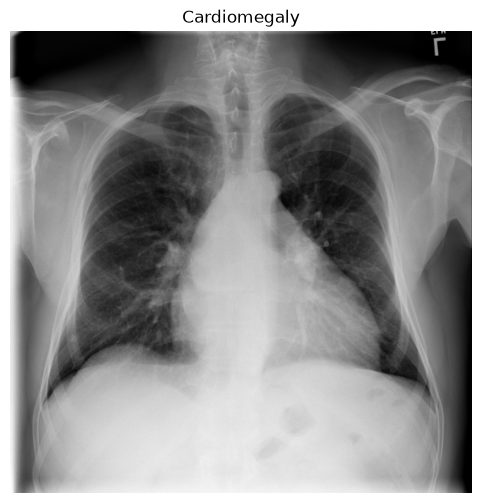

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.title(train_df.iloc[0]["Finding Labels"])
plt.show()

Check the clinical features

In [10]:
print(train_df["Patient Age"].describe())

print("\nSex:")
print(train_df["Patient Sex"].value_counts(dropna=False))

print("\nView Position:")
print(train_df["View Position"].value_counts(dropna=False))

count    69625.000000
mean        46.598276
std         16.699024
min          0.000000
25%         34.000000
50%         48.000000
75%         59.000000
max         95.000000
Name: Patient Age, dtype: float64

Sex:
Patient Sex
M    39366
F    30259
Name: count, dtype: int64

View Position:
View Position
PA    45104
AP    24521
Name: count, dtype: int64


In [13]:
import pandas as pd
import numpy as np

def prepare_clinical_features(df):
    df = df.copy()

    # Convert age to numeric
    df["Patient Age"] = pd.to_numeric(
        df["Patient Age"], errors="coerce"
    )

    # Replace missing age with median age
    df["Patient Age"] = df["Patient Age"].fillna(
        df["Patient Age"].median()
    )

    # Encode sex
    df["Sex_Encoded"] = df["Patient Sex"].map({
        "M": 1.0,
        "F": 0.0
    })

    # Encode view position
    df["View_Encoded"] = df["View Position"].map({
        "PA": 1.0,
        "AP": 0.0
    })

    return df

In [22]:
train_df = prepare_clinical_features(train_df)
val_df = prepare_clinical_features(val_df)
test_df = prepare_clinical_features(test_df)

print(train_df[[
    "Patient Age",
    "Sex_Encoded",
    "View_Encoded"
]].head())

   Patient Age  Sex_Encoded  View_Encoded
0           57          1.0           1.0
1           58          1.0           1.0
2           58          1.0           1.0
3           80          1.0           1.0
4           82          1.0           0.0


Image transformations

In [25]:
from torchvision import transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Create the multimodal Dataset

In [11]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

TARGET_LABELS = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

class MultimodalChestXrayDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_name = row["Image Index"]
        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        clinical = torch.tensor([
            float(row["Patient Age"]),
            float(row["Sex_Encoded"]),
            float(row["View_Encoded"])
        ], dtype=torch.float32)

        labels = torch.tensor(
            row[TARGET_LABELS].values.astype(np.float32),
            dtype=torch.float32
        )

        return image, clinical, labels

Create Dataset objects

In [26]:
IMAGE_DIR = "../data/raw/NIH_ChestXray14/images"

train_dataset = MultimodalChestXrayDataset(
    train_df,
    IMAGE_DIR,
    train_transform
)

val_dataset = MultimodalChestXrayDataset(
    val_df,
    IMAGE_DIR,
    eval_transform
)

test_dataset = MultimodalChestXrayDataset(
    test_df,
    IMAGE_DIR,
    eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 69625
Validation: 16899
Test: 25596


Test one sample

In [18]:
image, clinical, labels = train_dataset[0]

print("Image shape:", image.shape)
print("Clinical:", clinical)
print("Labels:", labels)

Image shape: torch.Size([3, 224, 224])
Clinical: tensor([57.,  1.,  1.])
Labels: tensor([0., 1., 0., 0., 0.])


Create DataLoaders

In [27]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [22]:
import os

available_images = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(".png")
]

print("Available images:", len(available_images))
print("Using image:", available_images[0])

Available images: 102120
Using image: 00000001_000.png


In [23]:
test_df_temp = train_df.iloc[[0]].copy()
test_df_temp["Image Index"] = available_images[0]

test_dataset = MultimodalChestXrayDataset(
    test_df_temp,
    IMAGE_DIR,
    eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

Test the train loader

In [29]:
images, clinical, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Clinical:", clinical.shape)
print("Labels:", labels.shape)

Images: torch.Size([16, 3, 224, 224])
Clinical: torch.Size([16, 3])
Labels: torch.Size([16, 5])


Baseline 1 — ResNet-18

Create a smaller subset for quick baseline training

In [30]:
TRAIN_SIZE = 10000
VAL_SIZE = 2000
TEST_SIZE = 2000

train_small = train_df.sample(
    n=min(TRAIN_SIZE, len(train_df)),
    random_state=42
).reset_index(drop=True)

val_small = val_df.sample(
    n=min(VAL_SIZE, len(val_df)),
    random_state=42
).reset_index(drop=True)

test_small = test_df.sample(
    n=min(TEST_SIZE, len(test_df)),
    random_state=42
).reset_index(drop=True)

print("Train:", len(train_small))
print("Validation:", len(val_small))
print("Test:", len(test_small))

Train: 10000
Validation: 2000
Test: 2000


Create loaders for baseline experiments

In [31]:
train_small_dataset = MultimodalChestXrayDataset(
    train_small,
    IMAGE_DIR,
    train_transform
)

val_small_dataset = MultimodalChestXrayDataset(
    val_small,
    IMAGE_DIR,
    eval_transform
)

test_small_dataset = MultimodalChestXrayDataset(
    test_small,
    IMAGE_DIR,
    eval_transform
)

train_small_loader = DataLoader(
    train_small_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_small_loader = DataLoader(
    val_small_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_small_loader = DataLoader(
    test_small_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Baseline loaders ready.")

Baseline loaders ready.


ResNet-18 model

In [34]:
resnet = models.resnet18(weights="DEFAULT")

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    len(TARGET_LABELS)
)

resnet = resnet.to(device)

print("ResNet-18 ready.")

ResNet-18 ready.


Loss and optimizer

In [35]:
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    resnet.parameters(),
    lr=1e-4
)

Train ResNet-18

In [38]:
resnet.train()

for epoch in range(1):

    running_loss = 0.0

    for images, clinical, labels in train_small_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_small_loader)

    print(
        f"Epoch {epoch + 1}/1 - Loss: {avg_loss:.4f}"
    )

Epoch 1/1 - Loss: 0.2285


Validate ResNet

In [39]:
resnet.eval()

val_loss = 0.0

with torch.no_grad():

    for images, clinical, labels in val_small_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)

        loss = criterion(outputs, labels)

        val_loss += loss.item()

val_loss /= len(val_small_loader)

print("Validation Loss:", val_loss)

Validation Loss: 0.22587600058317184


Baseline 2 — Clinical MLP

In [40]:
class ClinicalMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 5)
        )

    def forward(self, x):
        return self.network(x)

Create MLP

In [41]:
clinical_model = ClinicalMLP().to(device)

clinical_criterion = nn.BCEWithLogitsLoss()

clinical_optimizer = optim.Adam(
    clinical_model.parameters(),
    lr=1e-3
)

print("Clinical MLP ready.")

Clinical MLP ready.


Train Clinical MLP

In [42]:
clinical_model.train()

for epoch in range(5):

    running_loss = 0.0

    for images, clinical, labels in train_small_loader:

        clinical = clinical.to(device)
        labels = labels.to(device)

        clinical_optimizer.zero_grad()

        outputs = clinical_model(clinical)

        loss = clinical_criterion(outputs, labels)

        loss.backward()
        clinical_optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_small_loader)

    print(
        f"Epoch {epoch + 1}/5 - Loss: {avg_loss:.4f}"
    )

Epoch 1/5 - Loss: 0.2839
Epoch 2/5 - Loss: 0.2605
Epoch 3/5 - Loss: 0.2519
Epoch 4/5 - Loss: 0.2490
Epoch 5/5 - Loss: 0.2477


Baseline 3 — Basic Multimodal Fusion

Basic Fusion Model

In [43]:
class BasicFusionModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.image_encoder = models.resnet18(weights="DEFAULT")

        image_features = self.image_encoder.fc.in_features

        self.image_encoder.fc = nn.Identity()

        self.clinical_encoder = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(image_features + 16, 128),
            nn.ReLU(),
            nn.Linear(128, 5)
        )

    def forward(self, image, clinical):

        image_features = self.image_encoder(image)

        clinical_features = self.clinical_encoder(clinical)

        combined = torch.cat(
            [image_features, clinical_features],
            dim=1
        )

        output = self.classifier(combined)

        return output

Create Fusion Model

In [44]:
fusion_model = BasicFusionModel().to(device)

fusion_criterion = nn.BCEWithLogitsLoss()

fusion_optimizer = optim.Adam(
    fusion_model.parameters(),
    lr=1e-4
)

print("Basic multimodal fusion model ready.")

Basic multimodal fusion model ready.


Train Basic Fusion

In [45]:
fusion_model.train()

for epoch in range(1):

    running_loss = 0.0

    for images, clinical, labels in train_small_loader:

        images = images.to(device)
        clinical = clinical.to(device)
        labels = labels.to(device)

        fusion_optimizer.zero_grad()

        outputs = fusion_model(
            images,
            clinical
        )

        loss = fusion_criterion(
            outputs,
            labels
        )

        loss.backward()
        fusion_optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_small_loader)

    print(
        f"Epoch {epoch + 1}/1 - Loss: {avg_loss:.4f}"
    )

Epoch 1/1 - Loss: 0.2361


Validate Basic Fusion

In [46]:
fusion_model.eval()

val_loss = 0.0

with torch.no_grad():

    for images, clinical, labels in val_small_loader:

        images = images.to(device)
        clinical = clinical.to(device)
        labels = labels.to(device)

        outputs = fusion_model(
            images,
            clinical
        )

        loss = fusion_criterion(
            outputs,
            labels
        )

        val_loss += loss.item()

val_loss /= len(val_small_loader)

print("Fusion Validation Loss:", val_loss)

Fusion Validation Loss: 0.22494878381490707


Save all three baseline models

In [47]:
import os

os.makedirs("../results/checkpoints", exist_ok=True)

In [48]:
torch.save(
    resnet.state_dict(),
    "../results/checkpoints/resnet18_baseline.pth"
)

torch.save(
    clinical_model.state_dict(),
    "../results/checkpoints/clinical_mlp_baseline.pth"
)

torch.save(
    fusion_model.state_dict(),
    "../results/checkpoints/basic_fusion_baseline.pth"
)

print("All Phase A baseline models saved.")

All Phase A baseline models saved.


Phase B — Missing-modality handling and adaptive fusion

B1. Prepare clean data and clinical features

In [12]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    brier_score_loss
)

DATA_DIR = "../data/raw/NIH_ChestXray14"
PROCESSED_DIR = "../data/processed"
IMAGE_DIR = os.path.join(DATA_DIR, "images")

TARGET_LABELS = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))

def keep_existing_images(data):
    data = data.copy()

    exists = data["Image Index"].apply(
        lambda name: os.path.isfile(os.path.join(IMAGE_DIR, name))
    )

    print("Rows removed due to missing images:", int((~exists).sum()))

    return data.loc[exists].reset_index(drop=True)

train_df = keep_existing_images(train_df)
val_df = keep_existing_images(val_df)
test_df = keep_existing_images(test_df)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Rows removed due to missing images: 6157
Rows removed due to missing images: 1724
Rows removed due to missing images: 2119
Train: 63468
Validation: 15175
Test: 23477


In [13]:
def encode_clinical(data, age_median):
    data = data.copy()

    data["Patient Age"] = pd.to_numeric(
        data["Patient Age"], errors="coerce"
    )
    data["Patient Age"] = data["Patient Age"].fillna(age_median)

    data["Sex_Encoded"] = data["Patient Sex"].map({
        "M": 1.0,
        "F": 0.0
    }).fillna(0.5)

    data["View_Encoded"] = data["View Position"].map({
        "PA": 1.0,
        "AP": 0.0
    }).fillna(0.5)

    return data

age_median = pd.to_numeric(
    train_df["Patient Age"], errors="coerce"
).median()

train_df = encode_clinical(train_df, age_median)
val_df = encode_clinical(val_df, age_median)
test_df = encode_clinical(test_df, age_median)

CLINICAL_COLUMNS = [
    "Patient Age",
    "Sex_Encoded",
    "View_Encoded"
]

clinical_mean = train_df[CLINICAL_COLUMNS].mean()
clinical_std = train_df[CLINICAL_COLUMNS].std().replace(0, 1).fillna(1)

for data in [train_df, val_df, test_df]:
    data[CLINICAL_COLUMNS] = (
        data[CLINICAL_COLUMNS] - clinical_mean
    ) / clinical_std

print(train_df[CLINICAL_COLUMNS].head())
print("Clinical preprocessing complete.")

   Patient Age  Sex_Encoded  View_Encoded
0     0.630165     0.877057      0.734612
1     0.690338     0.877057      0.734612
2     0.690338     0.877057      0.734612
3     2.014140     0.877057      0.734612
4     2.134486     0.877057     -1.361241
Clinical preprocessing complete.


Rebuild the Dataset and DataLoaders

In [14]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MultimodalChestXrayDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = os.path.join(
            self.image_dir, row["Image Index"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        clinical = torch.tensor(
            row[CLINICAL_COLUMNS].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        labels = torch.tensor(
            row[TARGET_LABELS].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return image, clinical, labels

BATCH_SIZE = 16

train_dataset = MultimodalChestXrayDataset(
    train_df, IMAGE_DIR, train_transform
)
val_dataset = MultimodalChestXrayDataset(
    val_df, IMAGE_DIR, eval_transform
)
test_dataset = MultimodalChestXrayDataset(
    test_df, IMAGE_DIR, eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

images, clinical, labels = next(iter(train_loader))

print("Image batch:", images.shape)
print("Clinical batch:", clinical.shape)
print("Label batch:", labels.shape)

Image batch: torch.Size([16, 3, 224, 224])
Clinical batch: torch.Size([16, 3])
Label batch: torch.Size([16, 5])


Build the proposed adaptive fusion model

In [15]:
class AdaptiveFusionModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.image_encoder = models.resnet18(weights="DEFAULT")
        self.image_encoder.fc = nn.Identity()

        self.image_projection = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU()
        )

        self.clinical_encoder = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU()
        )

        self.image_gate = nn.Linear(128, 1)
        self.clinical_gate = nn.Linear(128, 1)

        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, len(TARGET_LABELS))
        )

    def forward(self, image, clinical, mask):
        image_features = self.image_encoder(image)
        image_features = self.image_projection(image_features)

        clinical_features = self.clinical_encoder(clinical)

        scores = torch.cat([
            self.image_gate(image_features),
            self.clinical_gate(clinical_features)
        ], dim=1)

        scores = scores.masked_fill(mask == 0, -1e4)
        weights = torch.softmax(scores, dim=1)

        fused_features = (
            weights[:, 0:1] * image_features
            + weights[:, 1:2] * clinical_features
        )

        predictions = self.classifier(fused_features)

        return predictions, weights

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

adaptive_model = AdaptiveFusionModel().to(device)

print("Device:", device)
print("Adaptive fusion model ready.")

Device: cuda
Adaptive fusion model ready.


In [16]:
class AdaptiveFusionModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.image_encoder = models.resnet18(weights="DEFAULT")
        self.image_encoder.fc = nn.Identity()

        self.image_projection = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU()
        )

        self.clinical_encoder = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU()
        )

        self.image_gate = nn.Linear(128, 1)
        self.clinical_gate = nn.Linear(128, 1)

        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, len(TARGET_LABELS))
        )

    def forward(self, image, clinical, mask):
        image_features = self.image_encoder(image)
        image_features = self.image_projection(image_features)

        clinical_features = self.clinical_encoder(clinical)

        scores = torch.cat([
            self.image_gate(image_features),
            self.clinical_gate(clinical_features)
        ], dim=1)

        scores = scores.masked_fill(mask == 0, -1e4)
        weights = torch.softmax(scores, dim=1)

        fused_features = (
            weights[:, 0:1] * image_features
            + weights[:, 1:2] * clinical_features
        )

        predictions = self.classifier(fused_features)

        return predictions, weights

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

adaptive_model = AdaptiveFusionModel().to(device)

print("Device:", device)
print("Adaptive fusion model ready.")

Device: cuda
Adaptive fusion model ready.


Add modality-dropout training

In [17]:
def make_training_mask(batch_size, device, drop_probability=0.25):
    mask = torch.ones(batch_size, 2, device=device)

    drop_image = (
        torch.rand(batch_size, device=device) < drop_probability
    )
    drop_clinical = (
        torch.rand(batch_size, device=device) < drop_probability
    )

    mask[drop_image, 0] = 0
    mask[drop_clinical, 1] = 0

    # Ensure at least one modality remains available.
    both_missing = mask.sum(dim=1) == 0
    mask[both_missing, 0] = 1

    return mask

example_mask = make_training_mask(8, device)

print(example_mask)

tensor([[1., 1.],
        [0., 1.],
        [1., 1.],
        [1., 1.],
        [1., 0.],
        [0., 1.],
        [1., 1.],
        [1., 1.]], device='cuda:0')


Train the adaptive model

In [18]:

import torch
import torch.nn as nn
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(adaptive_model.parameters(), lr=1e-4)

EPOCHS = 3
MAX_TRAIN_BATCHES = 50
MAX_VAL_BATCHES = 10

history = {"train_loss": [], "val_loss": []}

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(EPOCHS):
    adaptive_model.train()
    running_loss = 0.0
    train_count = 0

    for i, (images, clinical, labels) in enumerate(train_loader):
        if i >= MAX_TRAIN_BATCHES:
            break

        images = images.to(device, non_blocking=True)
        clinical = clinical.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        mask = make_training_mask(
            images.size(0), device, drop_probability=0.25
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs, _ = adaptive_model(images, clinical, mask)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        train_count += 1

    train_loss = running_loss / max(1, train_count)

    adaptive_model.eval()
    val_loss_total = 0.0
    val_count = 0

    with torch.no_grad():
        for i, (images, clinical, labels) in enumerate(val_loader):
            if i >= MAX_VAL_BATCHES:
                break

            images = images.to(device, non_blocking=True)
            clinical = clinical.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            mask = torch.ones(images.size(0), 2, device=device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs, _ = adaptive_model(images, clinical, mask)
                loss = criterion(outputs, labels)

            val_loss_total += loss.item()
            val_count += 1

    val_loss = val_loss_total / max(1, val_count)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )


Epoch 1/3 | Train Loss: 0.5083 | Validation Loss: 0.2978
Epoch 2/3 | Train Loss: 0.3365 | Validation Loss: 0.2415
Epoch 3/3 | Train Loss: 0.3144 | Validation Loss: 0.2381


Plot the training and validation losses:

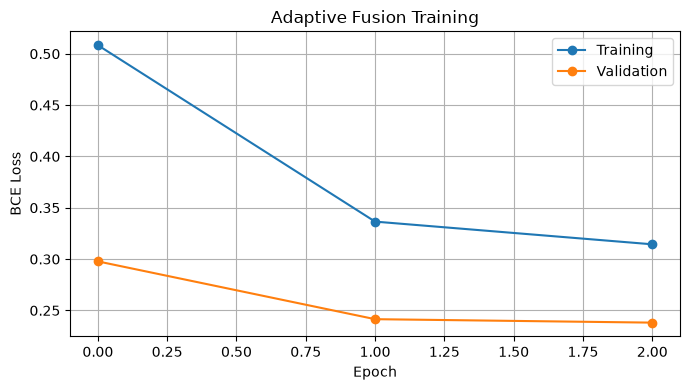

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], marker="o", label="Training")
plt.plot(history["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Adaptive Fusion Training")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Phase C — Evaluation and robustness testing

Create an evaluation function

In [20]:
def evaluate_model(model, loader, mode="both"):
    model.eval()

    all_labels = []
    all_probs = []
    all_weights = []

    with torch.no_grad():
        for images, clinical, labels in loader:
            images = images.to(device)
            clinical = clinical.to(device)
            labels = labels.to(device)

            batch_size = images.size(0)

            if mode == "both":
                mask = torch.ones(batch_size, 2, device=device)
            elif mode == "image_only":
                mask = torch.tensor(
                    [1.0, 0.0], device=device
                ).repeat(batch_size, 1)
            elif mode == "clinical_only":
                mask = torch.tensor(
                    [0.0, 1.0], device=device
                ).repeat(batch_size, 1)
            else:
                raise ValueError("Unknown evaluation mode")

            outputs, weights = model(
                images, clinical, mask
            )

            probs = torch.sigmoid(outputs)

            all_labels.append(labels.cpu().numpy())
            all_probs.append(probs.cpu().numpy())
            all_weights.append(weights.cpu().numpy())

    y_true = np.concatenate(all_labels)
    y_prob = np.concatenate(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    per_label_auc = []

    for i in range(len(TARGET_LABELS)):
        if len(np.unique(y_true[:, i])) == 2:
            per_label_auc.append(
                roc_auc_score(y_true[:, i], y_prob[:, i])
            )
        else:
            per_label_auc.append(np.nan)

    results = {
        "AUROC_macro": float(np.nanmean(per_label_auc)),
        "F1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_micro": f1_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "Precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Brier_score": brier_score_loss(
            y_true.ravel(), y_prob.ravel()
        )
    }

    return results, y_true, y_prob, np.concatenate(all_weights)

Compare missing-modality scenarios

In [ ]:
scenario_results = {}

for mode in ["both", "image_only", "clinical_only"]:
    metrics, y_true, y_prob, weights = evaluate_model(
        adaptive_model,
        test_loader,
        mode=mode
    )

    scenario_results[mode] = metrics

    print(f"\nScenario: {mode}")
    for name, value in metrics.items():
        print(f"{name}: {value:.4f}")

Create a comparison table:

In [23]:
scenario_table = pd.DataFrame(scenario_results).T

scenario_table.index = [
    "Both modalities",
    "CXR only",
    "Clinical only"
]

display(scenario_table.round(4))

""
Both modalities
CXR only
Clinical only


Save the results:

In [24]:
os.makedirs("../results/metrics", exist_ok=True)

scenario_table.to_csv(
    "../results/metrics/missing_modality_results.csv"
)

print("Scenario metrics saved.")

Scenario metrics saved.


Evaluate each disease separately

In [27]:

from itertools import islice

quick_test_loader = list(islice(test_loader, 10))

both_metrics, y_true, y_prob, both_weights = evaluate_model(
    adaptive_model, quick_test_loader, mode="both"
)

disease_table = per_disease_metrics(y_true, y_prob)
display(disease_table.round(4))

disease_table.to_csv(
    "../results/metrics/per_disease_results.csv",
    index=False
)


,Disease,AUROC,F1,Precision,Recall
0,Atelectasis,0.7258,0.0,0.0,0.0
1,Cardiomegaly,0.5017,0.0,0.0,0.0
2,Effusion,0.6070,0.0,0.0,0.0
3,Infiltration,0.6434,0.0,0.0,0.0
4,Pneumonia,0.7152,0.0,0.0,0.0


Plot ROC curves

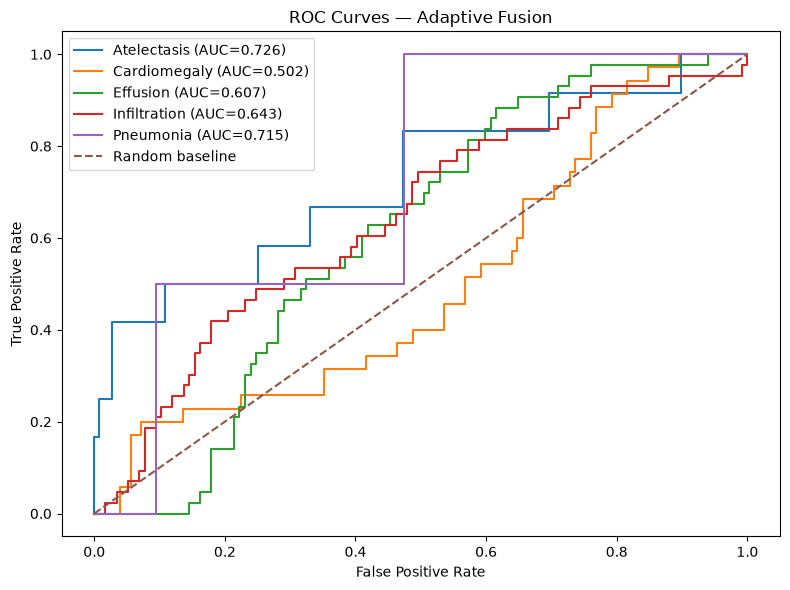

In [28]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for i, disease in enumerate(TARGET_LABELS):
    if len(np.unique(y_true[:, i])) < 2:
        continue

    fpr, tpr, _ = roc_curve(y_true[:, i], y_prob[:, i])

    plt.plot(
        fpr, tpr,
        label=f"{disease} (AUC={auc(fpr, tpr):.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Adaptive Fusion")
plt.legend()
plt.tight_layout()
plt.savefig(
    "../results/figures/adaptive_roc_curves.png",
    dpi=200
)
plt.show()

Phase D — Calibration, explainability, and final outputs

Save the trained model and preprocessing information

In [29]:
os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../results/figures", exist_ok=True)

torch.save({
    "model_state_dict": adaptive_model.state_dict(),
    "target_labels": TARGET_LABELS,
    "clinical_columns": CLINICAL_COLUMNS,
    "clinical_mean": clinical_mean.to_dict(),
    "clinical_std": clinical_std.to_dict(),
    "age_median": float(age_median)
}, "../results/checkpoints/adaptive_fusion_model.pth")

print("Adaptive fusion model saved.")

Adaptive fusion model saved.


Plot a calibration curve

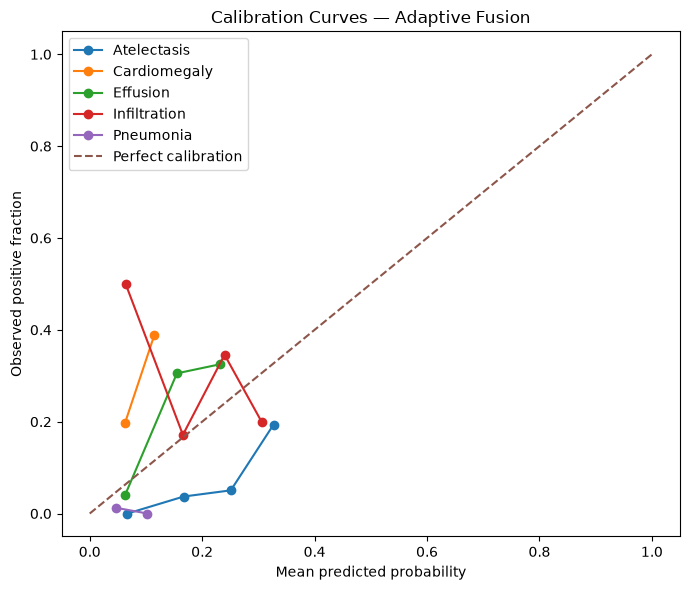

In [30]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(7, 6))

for i, disease in enumerate(TARGET_LABELS):
    if len(np.unique(y_true[:, i])) < 2:
        continue

    observed_fraction, mean_probability = calibration_curve(
        y_true[:, i],
        y_prob[:, i],
        n_bins=10,
        strategy="uniform"
    )

    plt.plot(
        mean_probability,
        observed_fraction,
        marker="o",
        label=disease
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Calibration Curves — Adaptive Fusion")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../results/figures/calibration_curves.png",
    dpi=200
)
plt.show()

Generate an image saliency map

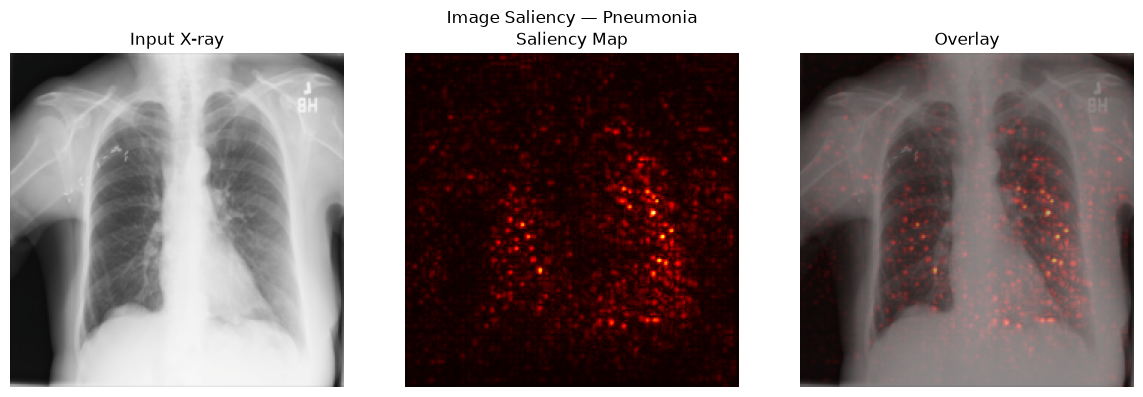

Predicted probability: 0.007945229299366474
Fusion weights [image, clinical]: [0.9982053  0.00179472]


In [31]:
def show_saliency_map(model, dataset, disease="Pneumonia"):
    model.eval()

    disease_index = TARGET_LABELS.index(disease)

    image, clinical, label = dataset[0]

    image_batch = image.unsqueeze(0).to(device)
    clinical_batch = clinical.unsqueeze(0).to(device)

    image_batch.requires_grad_(True)

    mask = torch.ones(1, 2, device=device)

    model.zero_grad()

    outputs, weights = model(
        image_batch, clinical_batch, mask
    )

    score = outputs[0, disease_index]
    score.backward()

    saliency = image_batch.grad.abs().max(dim=1)[0][0]
    saliency = saliency.detach().cpu().numpy()

    original = image.detach().cpu().permute(1, 2, 0).numpy()

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    original = np.clip(original * std + mean, 0, 1)

    saliency = saliency / (saliency.max() + 1e-8)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Input X-ray")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(saliency, cmap="hot")
    plt.title("Saliency Map")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original)
    plt.imshow(saliency, cmap="hot", alpha=0.45)
    plt.title("Overlay")
    plt.axis("off")

    plt.suptitle(f"Image Saliency — {disease}")
    plt.tight_layout()

    plt.savefig(
        f"../results/figures/saliency_{disease.lower()}.png",
        dpi=200
    )
    plt.show()

    print("Predicted probability:", torch.sigmoid(
        outputs[0, disease_index]
    ).item())
    print("Fusion weights [image, clinical]:", weights[0].detach().cpu().numpy())

show_saliency_map(
    adaptive_model,
    test_dataset,
    disease="Pneumonia"
)

Save the training history

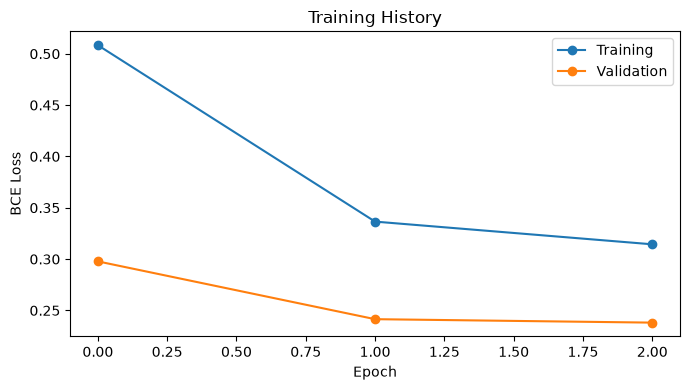

Training history and figures saved.


In [32]:
pd.DataFrame(history).to_csv(
    "../results/metrics/adaptive_training_history.csv",
    index=False
)

plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], marker="o", label="Training")
plt.plot(history["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training History")
plt.legend()
plt.tight_layout()
plt.savefig(
    "../results/figures/training_history.png",
    dpi=200
)
plt.show()

print("Training history and figures saved.")

Check the output files

In [33]:
for folder in [
    "../results/checkpoints",
    "../results/metrics",
    "../results/figures"
]:
    print("\n" + folder)

    for name in sorted(os.listdir(folder)):
        print(" -", name)


../results/checkpoints
 - adaptive_fusion_model.pth
 - basic_fusion_baseline.pth
 - clinical_mlp_baseline.pth
 - resnet18_baseline.pth

../results/metrics
 - adaptive_training_history.csv
 - missing_modality_results.csv
 - per_disease_results.csv

../results/figures
 - adaptive_roc_curves.png
 - calibration_curves.png
 - saliency_pneumonia.png
 - training_history.png
